<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/05-una-sola-prueba-puede-enganar/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 2.5 · Una sola prueba puede engañar

**Serie:** Del Excel al Machine Learning · **Temporada 2** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Por qué un solo periodo de prueba puede engañar.
- **Validación por ventanas**: repetir la prueba mes a mes.
- Cómo leer el resultado sin declarar un ganador que no existe.

## 📊 En Excel lo harías así

Armas una hoja donde pruebas tu fórmula con enero. Luego copias la hoja y pruebas con febrero, con marzo, y así. Al final, una tabla resumen con el error de cada mes.

Eso se llama **validación por ventanas**, y es tedioso en Excel. Con un bucle `for`, del 0.3, sale en una celda.

## 🐍 En Python

### Paso 1: lo mismo del 2.4

Traemos las funciones del episodio anterior. En noviembre, la regla y la regresión quedaron a la par. Probemos en otros dos meses:

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
FERIADOS = pd.to_datetime(
    [
        "2024-01-01",
        "2024-03-28",
        "2024-03-29",
        "2024-05-01",
        "2024-06-29",
        "2024-07-28",
        "2024-07-29",
        "2024-08-30",
        "2024-10-08",
        "2024-11-01",
        "2024-12-08",
        "2024-12-09",
        "2024-12-25",
        "2025-01-01",
        "2025-04-17",
        "2025-04-18",
        "2025-05-01",
        "2025-06-29",
        "2025-07-28",
        "2025-07-29",
        "2025-08-30",
        "2025-10-08",
        "2025-11-01",
        "2025-12-08",
        "2025-12-09",
        "2025-12-25",
    ]
)

In [3]:
def calendario(dias):
    """Una columna por día de la semana y por mes, más la tendencia: los días desde el inicio."""
    x = pd.DataFrame(index=dias)
    for dia in range(7):
        x[f"dia_{dia}"] = (dias.dayofweek == dia).astype(int)
    for mes in range(1, 13):
        x[f"mes_{mes}"] = (dias.month == mes).astype(int)
    x["tendencia"] = (dias - pd.Timestamp("2024-01-01")).days
    return x

In [4]:
def tres_pronosticos(serie, feriados, mes):
    """Pronostica cada día de un mes con tres métodos, usando solo lo anterior a ese mes."""
    inicio = pd.Timestamp(mes + "-01")
    dias = pd.date_range(inicio, inicio + pd.offsets.MonthEnd(0))
    antes = serie[serie.index < inicio]
    laborables = antes[~antes.index.isin(feriados)]

    # Promedio por día de la semana de las últimas 8 semanas.
    ultimas = laborables[laborables.index >= inicio - pd.Timedelta(days=56)]
    por_dia = ultimas.groupby(ultimas.index.dayofweek).mean()
    ocho_semanas = pd.Series(dias.dayofweek.map(por_dia), index=dias)

    # Índice: cuánto subió ese mes en 2024 frente a las 8 semanas previas de 2024.
    hace_un_anio = inicio - pd.Timedelta(days=364)
    base = laborables[
        (laborables.index >= hace_un_anio - pd.Timedelta(days=56))
        & (laborables.index < hace_un_anio)
    ]
    mismo_mes = laborables[
        (laborables.index.year == 2024) & (laborables.index.month == inicio.month)
    ]
    regla = ocho_semanas * mismo_mes.mean() / base.mean()

    modelo = LinearRegression().fit(calendario(laborables.index), laborables)
    regresion = pd.Series(modelo.predict(calendario(dias)), index=dias)

    # Todos los métodos ponen los feriados en cero: esos días no se vende.
    tabla = pd.DataFrame(
        {"real": serie[dias], "ocho_semanas": ocho_semanas, "regla": regla, "regresion": regresion}
    )
    metodos = ["ocho_semanas", "regla", "regresion"]
    tabla.loc[tabla.index.isin(feriados), metodos] = 0
    return tabla

In [5]:
ventas = pd.read_csv(DATOS + "ventas.csv", parse_dates=["fecha"])

serie = ventas.groupby("fecha")["total"].sum().asfreq("D", fill_value=0)

In [6]:
for mes in ["2025-08", "2025-09"]:
    tabla = tres_pronosticos(serie, FERIADOS, mes)
    regla = abs(tabla["real"].sum() - tabla["regla"].sum()).round(0)
    regresion = abs(tabla["real"].sum() - tabla["regresion"].sum()).round(0)
    print(mes, "regla", regla, "regresion", regresion)

2025-08 regla 20964.0 regresion 1147.0
2025-09 regla 7206.0 regresion 24396.0


Son errores en el **total del mes**. En agosto, la regresión casi lo clava, y la regla falla por mucho. En septiembre, al revés. Con un solo mes, podrías defender cualquiera de los dos. Y un número suelto en una reunión se ve muy convincente.

### Paso 2: las ventanas

Repetimos la prueba mes a mes. Cada mes usa **solo lo anterior a él**, como si ese fuera el día de hoy. Es la misma regla del 1.4.

Empezamos en marzo de 2025 porque la regla necesita las 8 semanas previas del año anterior.

In [7]:
def probar_en_ventanas(serie, feriados, meses):
    """Pronostica cada mes con lo anterior a él, y devuelve el error de cada método."""
    filas = []
    for mes in meses:
        tabla = tres_pronosticos(serie, feriados, mes)
        fila = {"mes": mes}
        for metodo in ["ocho_semanas", "regla", "regresion"]:
            fila[metodo] = (tabla["real"] - tabla[metodo]).abs().mean()
            fila[metodo + "_mes"] = abs(tabla["real"].sum() - tabla[metodo].sum())
        filas.append(fila)
    return pd.DataFrame(filas).set_index("mes").round(0)

In [8]:
meses = [f"2025-{numero:02d}" for numero in range(3, 13)]

ventanas = probar_en_ventanas(serie, FERIADOS, meses)

ventanas[["ocho_semanas", "regla", "regresion"]]

,ocho_semanas,regla,regresion
mes,,,
2025-03,3350.0,2923.0,2856.0
2025-04,1956.0,2027.0,1812.0
2025-05,2892.0,3257.0,3008.0
2025-06,3204.0,3177.0,3218.0
2025-07,4150.0,3710.0,3438.0
2025-08,2936.0,2608.0,2268.0
2025-09,4971.0,2485.0,2751.0
2025-10,2169.0,2250.0,2176.0
2025-11,4787.0,3035.0,3128.0


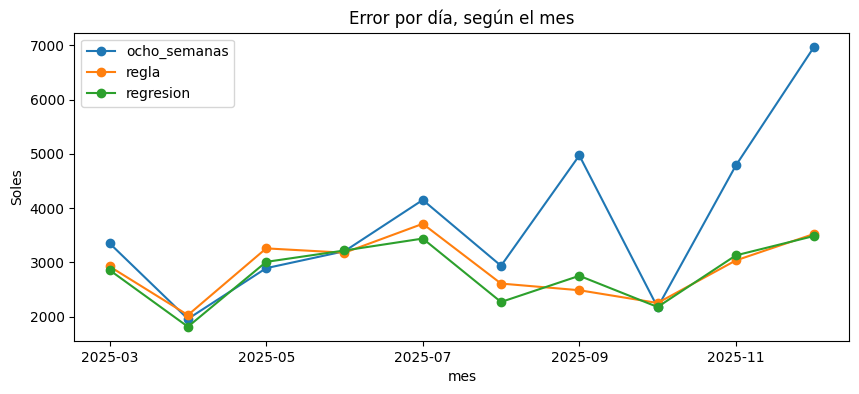

In [9]:
ventanas[["ocho_semanas", "regla", "regresion"]].plot(
    title="Error por día, según el mes", ylabel="Soles", figsize=(10, 4), marker="o"
)
plt.show()

Lee las líneas, no un punto. **La regla y la regresión se equivocan casi el doble en un mes que en otro.**

La tabla trae también las columnas `_mes`: `regla_mes` y `regresion_mes` son el error en el total del mes, el mismo del inicio.

### Paso 3: resumir sin engañar

In [10]:
gana_regresion = (ventanas["regresion"] < ventanas["regla"]).sum()

print(ventanas[["ocho_semanas", "regla", "regresion"]].mean().round(0))
print(ventanas[["regla_mes", "regresion_mes"]].mean().round(0))
print("Meses que gana la regresión por día:", gana_regresion, "de", len(ventanas))

ocho_semanas    3739.0
regla           2900.0
regresion       2814.0
dtype: float64
regla_mes        35578.0
regresion_mes    26344.0
dtype: float64
Meses que gana la regresión por día: 7 de 10


- **Lo firme:** el promedio simple se queda atrás cuando cambia el nivel de venta, como en septiembre, noviembre y diciembre. En los meses estables casi no hay diferencia.
- **Por día, la regla y la regresión empatan:** la diferencia es de un 3 %, poco frente a lo que cambia de un mes a otro.
- **Por total del mes, la regresión yerra menos en promedio** (unos 26 mil contra 36 mil), aunque cada método gana algunos meses. Si decides algo con el total del mes, como una compra, esto pesa.
- **Son 10 meses de un solo año.** Julio y diciembre aparecen una sola vez.

Para el pronóstico de cada día, entonces, la decisión no es matemática: una regla de Excel se explica sola y cualquiera la mantiene. Si empatan, **elige la que tu equipo pueda sostener**.

Y una nota de palabras: en el 2.2, la validación servía para elegir. Aquí, las ventanas son muchas pruebas seguidas.

> ⚠️ **Datos sintéticos**, con patrones programados.

## 🤖 Pídeselo a la IA

> *"Mi colega dice que su pronóstico es mejor porque ganó en el último mes. Explícame con un ejemplo por qué eso no basta, y qué es la validación por ventanas, sin fórmulas."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Copiar la hoja para cada mes | `for mes in meses:` |
| Probar solo con lo anterior | `tres_pronosticos(serie, FERIADOS, mes)` |
| Tabla de errores por mes | `probar_en_ventanas(serie, FERIADOS, meses)` |
| Contar los meses que gana | `(tabla["a"] < tabla["b"]).sum()` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/05-una-sola-prueba-puede-enganar/ejercicio.ipynb) y haz tu propia tabla. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/05-una-sola-prueba-puede-enganar/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0